# Machine Learning Final Project - Group 6

Members:

- Nguyễn Thành Long
- Vũ Đức Nguyên
- Nguyễn Tuấn Ninh

# HR Analytics: Job Change of Data Scientists

## About Dataset

### Context and Content

A company which is active in Big Data and Data Science wants to hire data scientists among people who successfully pass some courses which conduct by the company. Many people signup for their training. Company wants to know which of these candidates are really wants to work for the company after training or looking for a new employment because **it helps to reduce the cost and time as well as the quality of training or planning the courses and categorization of candidates**. Information related to demographics, education, experience are in hands from candidates signup and enrollment.

This dataset designed to understand the factors that lead a person to leave current job for HR researches too. By model(s) that uses the current credentials,demographics,experience data you will **predict the probability of a candidate to look for a new job or will work for the company, as well as interpreting affected factors on employee decision.**

The whole data divided to train and test . Target isn't included in test but the test target values data file is in hands for related tasks. A sample submission correspond to enrollee_id of test set provided too with columns : enrollee _id , target

Note:

- The dataset is imbalanced.
- Most features are categorical (Nominal, Ordinal, Binary), some with high cardinality.
- Missing imputation can be a part of your pipeline as well.

> **Features**
>
> - enrollee_id : Unique ID for candidate.
> - city: City code.
> - city_ development _index : Developement index of the city (scaled).
> - gender: Gender of candidate
> - relevent_experience: Relevant experience of candidate
> - enrolled_university: Type of University course enrolled if any
> - education_level: Education level of candidate
> - major_discipline :Education major discipline of candidate
> - experience: Candidate total experience in years
> - company_size: No of employees in current employer's company
> - company_type : Type of current employer
> - last_new_job: Difference in years between previous job and current job
> - training_hours: training hours completed
> - target: 0 – Not looking for job change, 1 – Looking for a job change

### Inspiration

- Predict the probability of a candidate will work for the company
- Interpret model(s) such a way that illustrate which features affect candidate decision

Please refer to the following task for more details:  
[https://www.kaggle.com/arashnic/hr-analytics-job-change-of-data-scientists/tasks?taskId=3015](https://www.kaggle.com/arashnic/hr-analytics-job-change-of-data-scientists/tasks?taskId=3015)

## Cài đặt thư viện

In [8]:
!pip install catboost

## Tải Dataset

In [9]:
import os
import shutil
import kagglehub
import pandas as pd

# 1. Download dataset via kagglehub
cache_path = kagglehub.dataset_download("arashnic/hr-analytics-job-change-of-data-scientists")

# 2. Copy files from cache to current working directory
for filename in os.listdir(cache_path):
    src_file = os.path.join(cache_path, filename)
    dst_file = os.path.join(os.getcwd(), filename)
    if os.path.isfile(src_file):
        shutil.copy(src_file, dst_file)

# 3. Verify files now exist in local working directory
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
print("CSV files in current directory:", csv_files)

# 4. Load datasets into Pandas
df_main = pd.read_csv('aug_train.csv')

print(f"\nTrain shape: {df_main.shape}")

# Preview first 5 rows
df_main.head()

Using Colab cache for faster access to the 'hr-analytics-job-change-of-data-scientists' dataset.
CSV files in current directory: ['aug_test.csv', 'sample_submission.csv', 'aug_train.csv']

Train shape: (19158, 14)


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


## Explanatory Data Analysis

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [11]:
# 1. Dataset overview
print("--- Dataset overview ---")
print(f"Total Rows: {df_main.shape[0]}")
print(f"Total Columns: {df_main.shape[1]}\n")

# Summary of data types and non-null counts
summary_df = pd.DataFrame(
    {
        "Data Type": df_main.dtypes,
        "Non-Null Count": df_main.notnull().sum(),
        "Unique Values": df_main.nunique(),
    }
)
print(summary_df)

--- Dataset overview ---
Total Rows: 19158
Total Columns: 14

                       Data Type  Non-Null Count  Unique Values
enrollee_id                int64           19158          19158
city                      object           19158            123
city_development_index   float64           19158             93
gender                    object           14650              3
relevent_experience       object           19158              2
enrolled_university       object           18772              3
education_level           object           18698              5
major_discipline          object           16345              6
experience                object           19093             22
company_size              object           13220              8
company_type              object           13018              6
last_new_job              object           18735              6
training_hours             int64           19158            241
target                   float64          


--- Missing values analysis ---
                     Missing Count  Percentage (%)
company_type                  6140           32.05
company_size                  5938           30.99
gender                        4508           23.53
major_discipline              2813           14.68
education_level                460            2.40
last_new_job                   423            2.21
enrolled_university            386            2.01
experience                      65            0.34


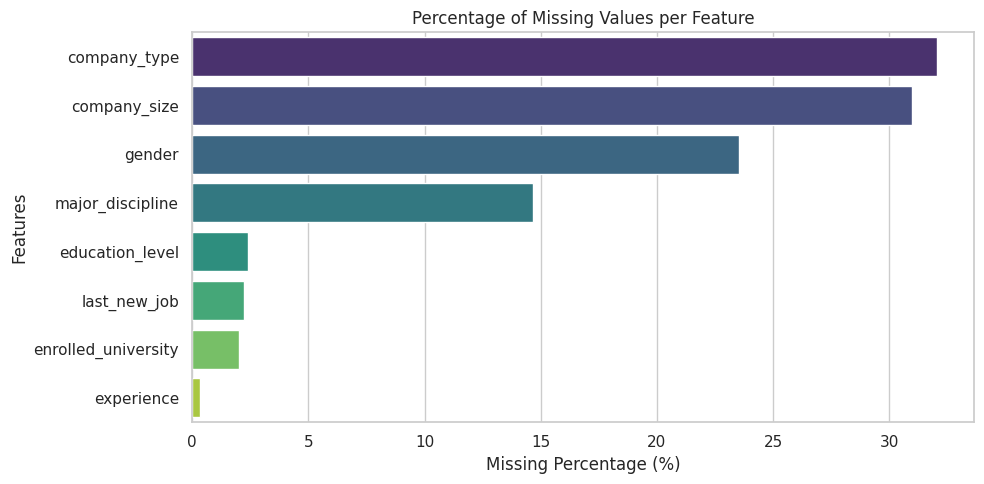

In [12]:
# 2. Missing values analysis
print("\n--- Missing values analysis ---")
missing_count = df_main.isnull().sum()
missing_percent = (df_main.isnull().sum() / len(df_main)) * 100

missing_df = (
    pd.DataFrame({"Missing Count": missing_count, "Percentage (%)": missing_percent})
    .query("`Missing Count` > 0")
    .sort_values(by="Percentage (%)", ascending=False)
)

print(missing_df.round(2))

# Plot Missing Values
if not missing_df.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=missing_df["Percentage (%)"],
        y=missing_df.index,
        hue=missing_df.index,
        legend=False,
        palette="viridis",
    )
    plt.title("Percentage of Missing Values per Feature")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()


--- Target distribution ---
        Count  Percentage (%)
target                       
0.0     14381           75.07
1.0      4777           24.93


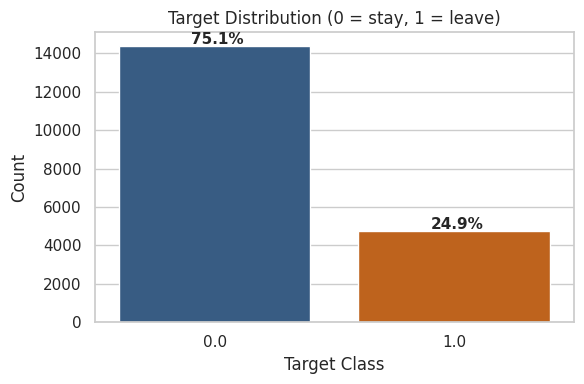

In [13]:
# 3. Target distribution
print("\n--- Target distribution ---")
target_counts = df_main["target"].value_counts(dropna=False)
target_props = df_main["target"].value_counts(normalize=True, dropna=False) * 100

target_summary = pd.DataFrame(
    {"Count": target_counts, "Percentage (%)": target_props.round(2)}
)
print(target_summary)

plt.figure(figsize=(6, 4))
ax = sns.countplot(
    x="target",
    data=df_main,
    hue="target",
    legend=False,
    palette=["#2b5c8f", "#d95f02"],
)
plt.title("Target Distribution (0 = stay, 1 = leave)")
plt.xlabel("Target Class")
plt.ylabel("Count")

# Add percentage annotations on top of bars
total = len(df_main)
for p in ax.patches:
    percentage = f"{100 * p.get_height() / total:.1f}%"
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + 100
    ax.annotate(percentage, (x, y), fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

In [14]:
# 4. Categorical & numerical summary
print("\n--- Numerical features summary ---")
display(df_main.describe().round(2))

print("\n--- Categorical features summary ---")
cat_cols = df_main.select_dtypes(include=["object"]).columns.tolist()
for col in cat_cols:
    print(
        f"\nFeature: {col} | Missing: {df_main[col].isnull().sum()} ({df_main[col].isnull().mean()*100:.1f}%)"
    )
    print(df_main[col].value_counts(dropna=False).head(5))


--- Numerical features summary ---


,enrollee_id,city_development_index,training_hours,target
count,19158.00,19158.00,19158.00,19158.00
mean,16875.36,0.83,65.37,0.25
std,9616.29,0.12,60.06,0.43
min,1.00,0.45,1.00,0.00
25%,8554.25,0.74,23.00,0.00
50%,16982.50,0.90,47.00,0.00
75%,25169.75,0.92,88.00,0.00
max,33380.00,0.95,336.00,1.00



--- Categorical features summary ---

Feature: city | Missing: 0 (0.0%)
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
Name: count, dtype: int64

Feature: gender | Missing: 4508 (23.5%)
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

Feature: relevent_experience | Missing: 0 (0.0%)
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

Feature: enrolled_university | Missing: 386 (2.0%)
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386
Name: count, dtype: int64

Feature: education_level | Missing: 460 (2.4%)
education_level
Graduate       11598
Masters         4361
High School     2017
NaN              460
Phd              414
Name: count, dtype: int64

Feature: major_discipline | Missing: 2813 (14.7%)
major_discipline
STEM               14492
NaN                 2

## Baseline: CatBoost mặc định trên dữ liệu thô với Stratified 5-Fold cross validation

* **Tiền xử lý dữ liệu**:
  * Các biến phân loại (`object`): Điền giá trị thiếu bằng nhãn `"Missing"` và chuyển đổi sang mã category số nguyên.
  * Các biến số thực: Điền giá trị thiếu bằng giá trị trung vị (median).
* **Thiết lập tham số**:
  * `iterations = 300`
  * `task_type = "GPU"`
  * `random_seed = 42`
  * `early_stopping_rounds = 50`
  * Tham số mặc định: `depth = 6`, `l2_leaf_reg = 3`, không sử dụng trọng số lớp (`auto_class_weights=None`).

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss, accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from catboost import CatBoostClassifier, Pool

# Hàm tính toán các chỉ số đánh giá và trả về dictionary
def evaluate_predictions(y_true, y_pred, y_proba):
    loss = log_loss(y_true, y_proba)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc = roc_auc_score(y_true, y_proba)

    metrics = {"log_loss": loss, "accuracy": acc, "f1_score": f1, "roc_auc": roc}
    return metrics

# Hàm riêng chuyên dùng để in kết quả đánh giá từ dictionary
def print_evaluation(metrics):
    print(f"LogLoss:   {metrics['log_loss']:.4f}")
    print(f"Accuracy:  {metrics['accuracy']:.4f}")
    print(f"F1-Score:  {metrics['f1_score']:.4f}")
    print(f"ROC-AUC:   {metrics['roc_auc']:.4f}")

# Hàm chung dùng để vẽ đồ thị Loss Curve từ mô hình CatBoost
def plot_loss_curve(model, title_suffix):
    evals_result = model.get_evals_result()
    plt.figure(figsize=(8, 5))
    plt.plot(evals_result['learn']['Logloss'], label='Train LogLoss', color='#2b5c8f')
    plt.plot(evals_result['validation']['Logloss'], label='Val LogLoss', color='#d95f02')
    plt.title(f'Loss Curve - {title_suffix}')
    plt.xlabel('Iterations')
    plt.ylabel('LogLoss')
    plt.legend()
    plt.show()

In [16]:
# Tách X và y
X_base = df_main.drop('target', axis=1).copy()
y_base = df_main['target'].copy()

# Xử lý missing values đơn giản
cat_cols = X_base.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_base.select_dtypes(include=[np.number]).columns.tolist()

for col in cat_cols:
    X_base[col] = X_base[col].astype(str).fillna("Missing")
for col in num_cols:
    X_base[col] = X_base[col].fillna(X_base[col].median())

In [17]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import log_loss, accuracy_score, f1_score, roc_auc_score

# Encode category thành số nguyên để chạy CV nhanh trên GPU
X_encoded = X_base.copy()
for col in cat_cols:
    X_encoded[col] = X_encoded[col].astype('category').cat.codes.astype(int)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_base = np.zeros(len(df_main))
oof_probas_base = np.zeros(len(df_main))
fold_losses = []
fold_aucs = []

In [18]:
print("=== HUẤN LUYỆN BASELINE VỚI STRATIFIED 5-FOLD CV ===")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
    print(f"\n--- Huấn luyện Fold {fold + 1} ---")
    X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
    X_va, y_va = X_encoded.iloc[val_idx], y_base.iloc[val_idx]

    train_pool = Pool(data=X_tr, label=y_tr)
    val_pool = Pool(data=X_va, label=y_va)

    model = CatBoostClassifier(
        task_type="GPU",
        iterations=300,
        random_seed=42,
        verbose=0
    )
    model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

    preds_proba = model.predict_proba(val_pool)[:, 1]
    loss_val = log_loss(y_va, preds_proba)
    auc_val = roc_auc_score(y_va, preds_proba)

    fold_losses.append(loss_val)
    fold_aucs.append(auc_val)

    print(f"Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

    oof_preds_base[val_idx] = model.predict(val_pool)
    oof_probas_base[val_idx] = preds_proba

print(f"\n-> Baseline Average LogLoss: {np.mean(fold_losses):.5f}")
print(f"-> Baseline Average ROC-AUC: {np.mean(fold_aucs):.5f}")

=== HUẤN LUYỆN BASELINE VỚI STRATIFIED 5-FOLD CV ===

--- Huấn luyện Fold 1 ---
Fold 1 hoàn thành - LogLoss: 0.43719 | ROC-AUC: 0.80283

--- Huấn luyện Fold 2 ---
Fold 2 hoàn thành - LogLoss: 0.43551 | ROC-AUC: 0.80358

--- Huấn luyện Fold 3 ---
Fold 3 hoàn thành - LogLoss: 0.43517 | ROC-AUC: 0.80453

--- Huấn luyện Fold 4 ---
Fold 4 hoàn thành - LogLoss: 0.43998 | ROC-AUC: 0.79740

--- Huấn luyện Fold 5 ---
Fold 5 hoàn thành - LogLoss: 0.42969 | ROC-AUC: 0.80851

-> Baseline Average LogLoss: 0.43551
-> Baseline Average ROC-AUC: 0.80337


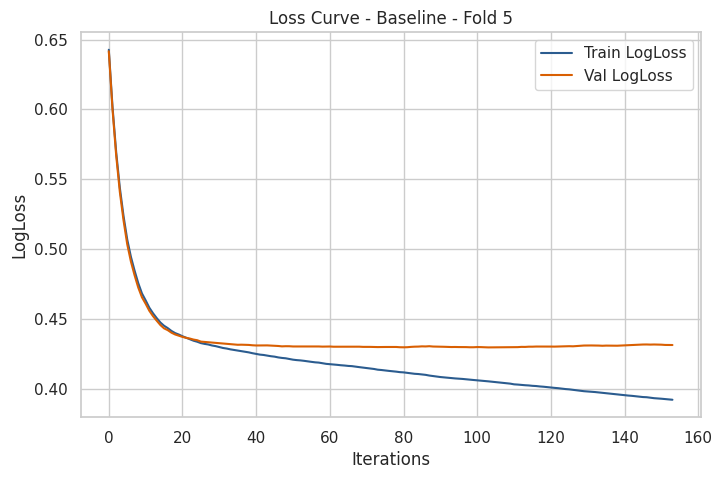

In [19]:
# Vẽ đồ thị Loss Curve đại diện sử dụng fold cuối cùng (Fold 5)
plot_loss_curve(model, "Baseline - Fold 5")

In [20]:
print("=== KẾT QUẢ BASELINE (Stratified 5-Fold CV) ===")
metrics_baseline = evaluate_predictions(y_base, oof_preds_base, oof_probas_base)
print_evaluation(metrics_baseline)

=== KẾT QUẢ BASELINE (Stratified 5-Fold CV) ===
LogLoss:   0.4355
Accuracy:  0.7944
F1-Score:  0.5733
ROC-AUC:   0.8034


### Đánh giá kết quả

* **Kết quả Baseline (Stratified 5-Fold OOF)**:
  * **LogLoss**: `0.4355`
  * **Accuracy**: `0.7944`
  * **F1-Score**: `0.5733`
  * **ROC-AUC**: `0.8034`
* **Nhận xét**: Mô hình Baseline đạt Accuracy tương đối cao (79.44%) và LogLoss thấp do hàm mục tiêu ưu tiên lớp đa số (0). Tuy nhiên, chỉ số F1-Score chỉ đạt **0.5733**, cho thấy khả năng nhận diện ứng viên muốn chuyển việc (lớp 1) còn thấp.


## Cải tiến 1: Thêm `auto_class_weights='Balanced'`

* **Mục tiêu**: Xử lý tình trạng thiên lệch dự đoán về lớp 0 do mất cân bằng tỷ lệ 3:1.
* **Phương pháp**: Kích hoạt tham số `auto_class_weights='Balanced'`. Trọng số của mỗi lớp được tính theo công thức:
  $$w_c = \frac{N}{2 \times N_c}$$
  Với tỷ lệ 75:25, các mẫu thuộc lớp 1 nhận trọng số phạt xấp xỉ gấp 3 lần so với lớp 0 trong hàm tổn thất khi phân nhánh cây.

In [21]:
oof_preds_cv1 = np.zeros(len(df_main))
oof_probas_cv1 = np.zeros(len(df_main))
fold_losses_cv1 = []
fold_aucs_cv1 = []

In [22]:
print("=== HUẤN LUYỆN CẢI TIẾN 1 VỚI CLASS BALANCING (5-FOLD CV) ===")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
    print(f"\n--- Huấn luyện Fold {fold + 1} ---")
    X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
    X_va, y_va = X_encoded.iloc[val_idx], y_base.iloc[val_idx]

    train_pool = Pool(data=X_tr, label=y_tr)
    val_pool = Pool(data=X_va, label=y_va)

    model = CatBoostClassifier(
        task_type="GPU",
        iterations=300,
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0
    )
    model.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

    preds_proba = model.predict_proba(val_pool)[:, 1]
    loss_val = log_loss(y_va, preds_proba)
    auc_val = roc_auc_score(y_va, preds_proba)

    fold_losses_cv1.append(loss_val)
    fold_aucs_cv1.append(auc_val)

    print(f"Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

    oof_preds_cv1[val_idx] = model.predict(val_pool)
    oof_probas_cv1[val_idx] = preds_proba

print(f"\n-> Cải tiến 1 Average LogLoss: {np.mean(fold_losses_cv1):.5f}")
print(f"-> Cải tiến 1 Average ROC-AUC: {np.mean(fold_aucs_cv1):.5f}")

=== HUẤN LUYỆN CẢI TIẾN 1 VỚI CLASS BALANCING (5-FOLD CV) ===

--- Huấn luyện Fold 1 ---
Fold 1 hoàn thành - LogLoss: 0.51668 | ROC-AUC: 0.80499

--- Huấn luyện Fold 2 ---
Fold 2 hoàn thành - LogLoss: 0.52133 | ROC-AUC: 0.80350

--- Huấn luyện Fold 3 ---
Fold 3 hoàn thành - LogLoss: 0.51801 | ROC-AUC: 0.80554

--- Huấn luyện Fold 4 ---
Fold 4 hoàn thành - LogLoss: 0.53095 | ROC-AUC: 0.79555

--- Huấn luyện Fold 5 ---
Fold 5 hoàn thành - LogLoss: 0.50743 | ROC-AUC: 0.80998

-> Cải tiến 1 Average LogLoss: 0.51888
-> Cải tiến 1 Average ROC-AUC: 0.80391


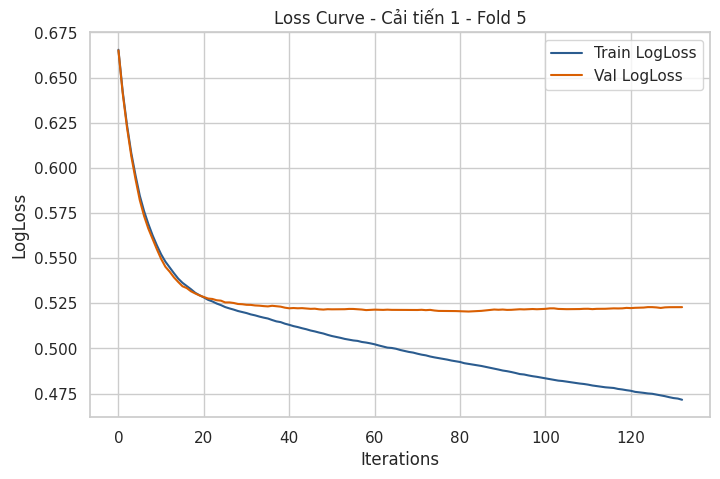

In [23]:
# Vẽ đồ thị Loss Curve đại diện sử dụng fold cuối cùng (Fold 5)
plot_loss_curve(model, "Cải tiến 1 - Fold 5")

In [24]:
print("=== KẾT QUẢ CẢI TIẾN 1 (Stratified 5-Fold CV) ===")
metrics_cv1 = evaluate_predictions(y_base, oof_preds_cv1, oof_probas_cv1)
print_evaluation(metrics_cv1)

=== KẾT QUẢ CẢI TIẾN 1 (Stratified 5-Fold CV) ===
LogLoss:   0.5189
Accuracy:  0.7798
F1-Score:  0.6296
ROC-AUC:   0.8038


### Đánh giá kết quả

* **Kết quả Cải tiến 1 (Stratified 5-Fold OOF)**:
  * **LogLoss**: `0.5189`
  * **Accuracy**: `0.7798`
  * **F1-Score**: **`0.6296`** *(Tăng mạnh từ `0.5733` lên `0.6296`)*
  * **ROC-AUC**: **`0.8038`** *(Tăng nhẹ từ `0.8034` lên `0.8038`)*
* **Nhận xét**: F1-Score tăng mạnh chứng tỏ việc gán trọng số giúp mô hình nâng cao độ nhạy (Recall) đối với nhóm ứng viên muốn chuyển việc, hạn chế việc bỏ sót đối tượng mục tiêu.

## Cải tiến 2: Grid Search điều chỉnh hyperparameters

* **Mục tiêu**: Tìm kiếm sự kết hợp phù hợp giữa độ sâu của cây và hệ số điều chuẩn L2 để kiểm soát hiện tượng quá khớp (overfitting) và cải thiện ROC-AUC.
* **Không gian tìm kiếm (Parameter Grid)**:
  * `depth`: $[4, 5, 6, 7, 8]$
  * `l2_leaf_reg`: $[1, 3, 5, 7, 10]$
  * Tổng cộng 25 cấu hình, mỗi cấu hình được đánh giá qua Stratified 5-Fold CV.

In [25]:
# Định nghĩa lưới tham số tinh giản mới
depths = [4, 5, 6, 7, 8]
l2s = [1, 3, 5, 7, 10]

best_params = None
best_cv_auc = -float('inf')  # Khởi tạo giá trị AUC tốt nhất là âm vô cùng

# dictionary lưu mô hình theo hyperparameter tuple
parameter_models_dictionary = {}

parameter_oof_probas = {}
parameter_oof_preds = {}

In [26]:
print("=== BẮT ĐẦU GRID SEARCH VÀ LƯU MÔ HÌNH VÀO DICTIONARY (ĐÁNH GIÁ BẰNG ROC-AUC) ===")
for d in depths:
    for l2 in l2s:
        param_key = (d, l2)
        fold_aucs = []
        fold_losses_temp = []
        temp_models = []
        temp_oof_preds = np.zeros(len(df_main))
        temp_oof_probas = np.zeros(len(df_main))

        print(f"\nThử nghiệm cấu hình: depth={d}, l2_leaf_reg={l2}")
        for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
            X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
            X_va, y_va = X_encoded.iloc[val_idx], y_base.iloc[val_idx]

            model = CatBoostClassifier(
                task_type="GPU",
                iterations=300,
                depth=d,
                l2_leaf_reg=l2,
                auto_class_weights='Balanced',
                random_seed=42,
                verbose=0
            )
            model.fit(Pool(X_tr, y_tr), eval_set=Pool(X_va, y_va), early_stopping_rounds=50)

            preds_proba = model.predict_proba(X_va)[:, 1]
            loss_val = log_loss(y_va, preds_proba)
            auc_val = roc_auc_score(y_va, preds_proba)

            fold_losses_temp.append(loss_val)
            fold_aucs.append(auc_val)

            print(f"  -> Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

            temp_oof_preds[val_idx] = model.predict(X_va)
            temp_oof_probas[val_idx] = preds_proba
            temp_models.append(model)

        mean_auc = np.mean(fold_aucs)
        mean_loss = np.mean(fold_losses_temp)
        print(f"=> Kết quả cấu hình: Mean CV LogLoss: {mean_loss:.5f} | Mean CV ROC-AUC: {mean_auc:.5f}")

        parameter_models_dictionary[param_key] = temp_models
        parameter_oof_preds[param_key] = temp_oof_preds
        parameter_oof_probas[param_key] = temp_oof_probas

        # Chọn cấu hình tối ưu dựa trên ROC-AUC cao nhất
        if mean_auc > best_cv_auc:
            best_cv_auc = mean_auc
            best_params = {'depth': d, 'l2_leaf_reg': l2}

best_key = (best_params['depth'], best_params['l2_leaf_reg'])
print(f"\n-> Cấu hình tối ưu nhất theo ROC-AUC: {best_params} với ROC-AUC: {best_cv_auc:.5f}")

=== BẮT ĐẦU GRID SEARCH VÀ LƯU MÔ HÌNH VÀO DICTIONARY (ĐÁNH GIÁ BẰNG ROC-AUC) ===

Thử nghiệm cấu hình: depth=4, l2_leaf_reg=1
  -> Fold 1 hoàn thành - LogLoss: 0.52660 | ROC-AUC: 0.80063
  -> Fold 2 hoàn thành - LogLoss: 0.52804 | ROC-AUC: 0.80299
  -> Fold 3 hoàn thành - LogLoss: 0.52433 | ROC-AUC: 0.80338
  -> Fold 4 hoàn thành - LogLoss: 0.53387 | ROC-AUC: 0.79799
  -> Fold 5 hoàn thành - LogLoss: 0.51719 | ROC-AUC: 0.80697
=> Kết quả cấu hình: Mean CV LogLoss: 0.52600 | Mean CV ROC-AUC: 0.80239

Thử nghiệm cấu hình: depth=4, l2_leaf_reg=3
  -> Fold 1 hoàn thành - LogLoss: 0.52659 | ROC-AUC: 0.80055
  -> Fold 2 hoàn thành - LogLoss: 0.52807 | ROC-AUC: 0.80287
  -> Fold 3 hoàn thành - LogLoss: 0.52417 | ROC-AUC: 0.80365
  -> Fold 4 hoàn thành - LogLoss: 0.53415 | ROC-AUC: 0.79777
  -> Fold 5 hoàn thành - LogLoss: 0.51707 | ROC-AUC: 0.80676
=> Kết quả cấu hình: Mean CV LogLoss: 0.52601 | Mean CV ROC-AUC: 0.80232

Thử nghiệm cấu hình: depth=4, l2_leaf_reg=5
  -> Fold 1 hoàn thành - Lo

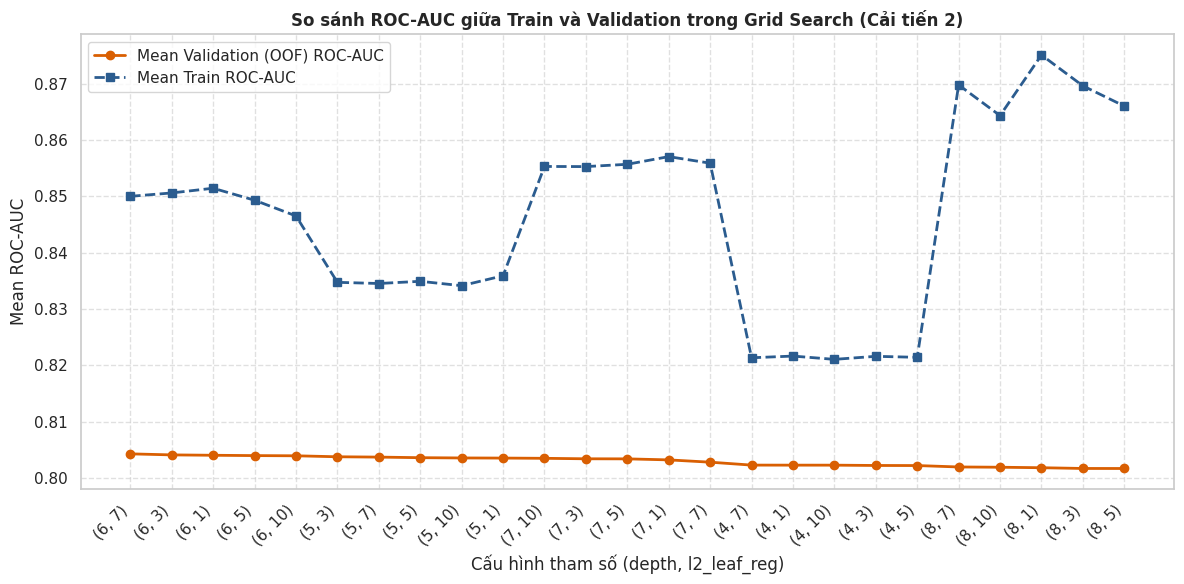

In [27]:
# Vẽ đồ thị so sánh ROC-AUC trên cả Train và Validation (OOF) của tất cả các cấu hình trong Grid Search (Cải tiến 2)
grid_val_results = {}
grid_train_results = {}

for param_key, models in parameter_models_dictionary.items():
    # 1. Tính OOF Validation ROC-AUC
    oof_probs = parameter_oof_probas[param_key]
    val_auc = roc_auc_score(y_base, oof_probs)
    grid_val_results[str(param_key)] = val_auc

    # 2. Tính Train ROC-AUC trung bình trên 5 Folds
    fold_train_aucs = []
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_encoded, y_base)):
        X_tr, y_tr = X_encoded.iloc[train_idx], y_base.iloc[train_idx]
        model = models[fold]
        train_probs = model.predict_proba(X_tr)[:, 1]
        fold_train_aucs.append(roc_auc_score(y_tr, train_probs))

    grid_train_results[str(param_key)] = np.mean(fold_train_aucs)

# Sắp xếp các cấu hình theo Validation ROC-AUC giảm dần (từ tốt nhất đến kém nhất)
sorted_val_results = sorted(grid_val_results.items(), key=lambda x: x[1], reverse=True)
param_labels = [item[0] for item in sorted_val_results]
val_aucs = [item[1] for item in sorted_val_results]
train_aucs = [grid_train_results[label] for label in param_labels]

plt.figure(figsize=(12, 6))
plt.plot(param_labels, val_aucs, marker='o', color='#d95f02', linewidth=2, markersize=6, label='Mean Validation (OOF) ROC-AUC')
plt.plot(param_labels, train_aucs, marker='s', color='#2b5c8f', linewidth=2, markersize=6, linestyle='--', label='Mean Train ROC-AUC')
plt.title('So sánh ROC-AUC giữa Train và Validation trong Grid Search (Cải tiến 2)', fontsize=12, fontweight='bold')
plt.xlabel('Cấu hình tham số (depth, l2_leaf_reg)')
plt.ylabel('Mean ROC-AUC')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

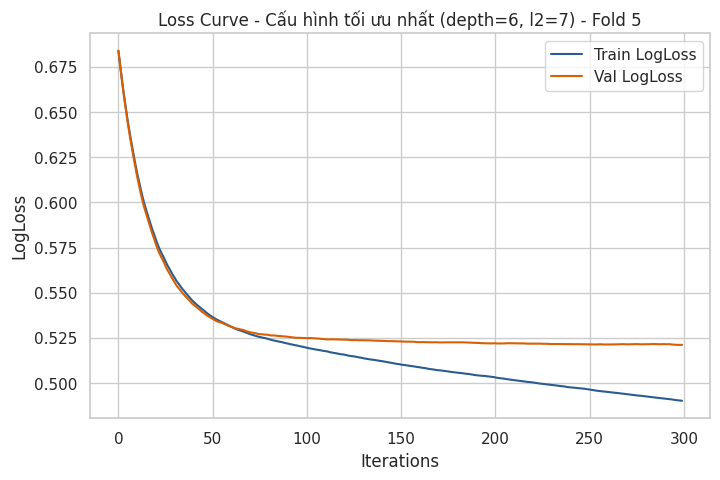

In [28]:
# vẽ Loss Curve cho cấu hình tối ưu nhất (sử dụng Fold cuối làm đại diện)
best_model_representative = parameter_models_dictionary[best_key][-1]
plot_loss_curve(best_model_representative, f"Cấu hình tối ưu nhất (depth={best_params['depth']}, l2={best_params['l2_leaf_reg']}) - Fold 5")

In [29]:
# Lấy trực tiếp kết quả OOF và mô hình tốt nhất từ dictionary
final_best_key = (best_params['depth'], best_params['l2_leaf_reg'])
oof_preds_cv2 = parameter_oof_preds[final_best_key]
oof_probas_cv2 = parameter_oof_probas[final_best_key]
model_cv2 = parameter_models_dictionary[final_best_key][-1]

In [30]:
print("=== KẾT QUẢ CẢI TIẾN 2 (Grid Search Hyperparameters) ===")
metrics_cv2 = evaluate_predictions(y_base, oof_preds_cv2, oof_probas_cv2)
print_evaluation(metrics_cv2)

=== KẾT QUẢ CẢI TIẾN 2 (Grid Search Hyperparameters) ===
LogLoss:   0.5189
Accuracy:  0.7811
F1-Score:  0.6311
ROC-AUC:   0.8043


### Đánh giá kết quả

* **Kết quả Grid Search**:
  * Khi tăng độ sâu lên 7 và 8, điểm ROC-AUC trên tập huấn luyện tiếp tục tăng nhưng điểm kiểm định trên fold (Validation ROC-AUC) có xu hướng đi ngang hoặc giảm, phản ánh nguy cơ overfitting ở các cây có cấu trúc phức tạp.
  * **Cấu hình tối ưu ghi nhận**: `depth = 6`, `l2_leaf_reg = 7` với điểm Mean CV ROC-AUC đạt **0.80449**.
* **Kết quả Cải tiến 2 trên toàn bộ tập OOF**:
  * **LogLoss**: `0.5189`
  * **Accuracy**: `0.7810`
  * **F1-Score**: **`0.6311`**
  * **ROC-AUC**: **`0.8043`**
* **Nhận xét**: Việc nâng hệ số regularization `l2_leaf_reg` từ 3 lên 7 giúp kiểm soát variance ở các nút lá, cải thiện đồng thời cả Accuracy (lên 0.7810), F1-Score (lên 0.6311) và ROC-AUC (lên 0.8043).

## Cải tiến 3: Thêm Feature Engineering

* **Mục tiêu**: Khai thác thông tin về tính liên tục của thâm niên công tác và tỷ lệ thay đổi công việc để bổ sung tín hiệu định lượng cho mô hình.
* **Cơ sở phân tích**:
  * Hai đặc trưng `experience` và `last_new_job` ban đầu được biểu diễn dưới dạng chuỗi (text/categorical: `'<1'`, `'1'`, ..., `'>20'` và `'never'`, `'1'`, ..., `'>4'`).
  * Việc để nguyên dạng danh mục không phản ánh được quan hệ thứ bậc số học và tỷ số thời gian gắn bó giữa các lần chuyển việc.
* **Quy trình sinh đặc trưng**:
  1. **`experience_num`**: Chuyển đổi `experience` thành biến số thực liên tục:
     * `'<1'` $\rightarrow 0.0$, `'>20'` $\rightarrow 21.0$, các giá trị từ 1 đến 20 chuyển sang kiểu số thực, giá trị thiếu gán bằng median ($10.0$).
  2. **`last_new_job_num`**: Chuyển đổi `last_new_job` thành biến số thực liên tục:
     * `'never'` $\rightarrow 0.0$, `'>4'` $\rightarrow 5.0$, các giá trị số giữ nguyên, giá trị thiếu gán bằng $1.0$.
  3. **`experience_per_job`**: Tạo đặc trưng tỷ lệ thể hiện thời gian gắn bó bình quân trên mỗi lần thay đổi công việc:
     $$\text{experience\_per\_job} = \frac{\text{experience\_num}}{\text{last\_new\_job\_num} + 1}$$
     *Ý nghĩa*: Ứng viên có thâm niên làm việc cao nhưng ít lần đổi việc sẽ có tỷ số này cao (mức độ ổn định cao). Ngược lại, ứng viên có thâm niên thấp nhưng đổi việc nhiều lần sẽ có tỷ số thấp (xu hướng dịch chuyển công việc thường xuyên).

In [31]:
# Thực hiện Feature Engineering thêm đặc trưng để làm giàu thông tin
X_fe = X_base.copy()

# 1. Chuyển đổi 'experience' sang dạng số liên tục
def parse_experience(val):
    val = str(val).strip()
    if val == '<1': return 0
    if val == '>20': return 21
    try:
        return float(val)
    except:
        return 10.0 # Trung vị thay thế nếu lỗi

X_fe['experience_num'] = X_fe['experience'].apply(parse_experience)

# 2. Chuyển đổi 'last_new_job' sang dạng số liên tục
def parse_last_new_job(val):
    val = str(val).strip()
    if val == 'never': return 0
    if val == '>4': return 5
    try:
        return float(val)
    except:
        return 1.0

X_fe['last_new_job_num'] = X_fe['last_new_job'].apply(parse_last_new_job)

# 3. Tạo đặc trưng ổn định nghề nghiệp experience_per_job
X_fe['experience_per_job'] = X_fe['experience_num'] / (X_fe['last_new_job_num'] + 1)

# Encode category thành dạng số nguyên trước khi nạp vào CatBoost CV
X_fe_encoded = X_fe.copy()
for col in cat_cols:
    X_fe_encoded[col] = X_fe_encoded[col].astype('category').cat.codes.astype(int)

In [32]:
# Huấn luyện 5-Fold CV cho Cải tiến 3 kết hợp Feature Engineering
oof_preds_cv3 = np.zeros(len(df_main))
oof_probas_cv3 = np.zeros(len(df_main))
fold_losses_cv3 = []

In [33]:
print("=== HUẤN LUYỆN CẢI TIẾN 3 VỚI FEATURE ENGINEERING (5-FOLD CV) ===")
oof_preds_cv3 = np.zeros(len(df_main))
oof_probas_cv3 = np.zeros(len(df_main))
fold_losses_cv3 = []
fold_aucs_cv3 = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_fe_encoded, y_base)):
    print(f"\n--- Huấn luyện Fold {fold + 1} ---")
    X_tr, y_tr = X_fe_encoded.iloc[train_idx], y_base.iloc[train_idx]
    X_va, y_va = X_fe_encoded.iloc[val_idx], y_base.iloc[val_idx]

    train_pool = Pool(data=X_tr, label=y_tr)
    val_pool = Pool(data=X_va, label=y_va)

    # Sử dụng siêu tham số tối ưu mới tìm được theo ROC-AUC
    model_cv3 = CatBoostClassifier(
        task_type="GPU",
        iterations=300,
        depth=best_params['depth'],
        l2_leaf_reg=best_params['l2_leaf_reg'],
        auto_class_weights='Balanced',
        random_seed=42,
        verbose=0
    )
    model_cv3.fit(train_pool, eval_set=val_pool, early_stopping_rounds=50)

    preds_proba = model_cv3.predict_proba(val_pool)[:, 1]
    loss_val = log_loss(y_va, preds_proba)
    auc_val = roc_auc_score(y_va, preds_proba)

    fold_losses_cv3.append(loss_val)
    fold_aucs_cv3.append(auc_val)

    print(f"Fold {fold + 1} hoàn thành - LogLoss: {loss_val:.5f} | ROC-AUC: {auc_val:.5f}")

    oof_preds_cv3[val_idx] = model_cv3.predict(val_pool)
    oof_probas_cv3[val_idx] = preds_proba

print(f"\n-> Cải tiến 3 Average LogLoss: {np.mean(fold_losses_cv3):.5f}")
print(f"-> Cải tiến 3 Average ROC-AUC: {np.mean(fold_aucs_cv3):.5f}")

=== HUẤN LUYỆN CẢI TIẾN 3 VỚI FEATURE ENGINEERING (5-FOLD CV) ===

--- Huấn luyện Fold 1 ---
Fold 1 hoàn thành - LogLoss: 0.51679 | ROC-AUC: 0.80539

--- Huấn luyện Fold 2 ---
Fold 2 hoàn thành - LogLoss: 0.52186 | ROC-AUC: 0.80503

--- Huấn luyện Fold 3 ---
Fold 3 hoàn thành - LogLoss: 0.51720 | ROC-AUC: 0.80686

--- Huấn luyện Fold 4 ---
Fold 4 hoàn thành - LogLoss: 0.52782 | ROC-AUC: 0.80067

--- Huấn luyện Fold 5 ---
Fold 5 hoàn thành - LogLoss: 0.51036 | ROC-AUC: 0.80740

-> Cải tiến 3 Average LogLoss: 0.51881
-> Cải tiến 3 Average ROC-AUC: 0.80507


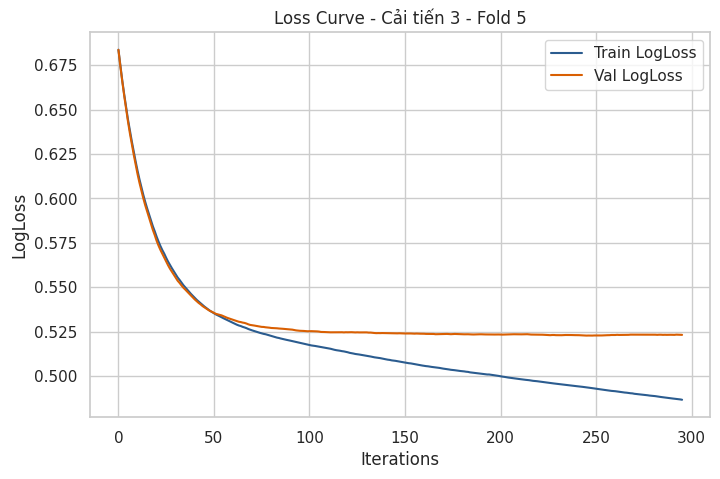

In [34]:
# Vẽ đồ thị Loss Curve đại diện sử dụng fold cuối cùng (Fold 5)
plot_loss_curve(model_cv3, "Cải tiến 3 - Fold 5")

In [35]:
print("=== KẾT QUẢ CẢI TIẾN 3 (Feature Engineering) ===")
metrics_cv3 = evaluate_predictions(y_base, oof_preds_cv3, oof_probas_cv3)
print_evaluation(metrics_cv3)

=== KẾT QUẢ CẢI TIẾN 3 (Feature Engineering) ===
LogLoss:   0.5188
Accuracy:  0.7808
F1-Score:  0.6307
ROC-AUC:   0.8049


### Đánh giá kết quả

* **Kết quả Cải tiến 3 (Stratified 5-Fold OOF)**:
  * **LogLoss**: **`0.5188`**
  * **Accuracy**: `0.7808`
  * **F1-Score**: `0.6307`
  * **ROC-AUC**: **`0.8049`**
* **Nhận xét**: Chỉ số ROC-AUC đạt mức cao nhất (0.8049) và LogLoss giảm xuống 0.5188, cho thấy đặc trưng mới đã cung cấp thêm thông tin phân tách hữu ích cho mô hình.

### Feature Importance

Trích xuất độ quan trọng của đặc trưng (Feature Importance) từ `get_feature_importance()` cho thấy cả hai đặc trưng sinh mới trong Cải tiến 3 `experience_per_job` & `experience_num` đều lọt vào nhóm đặc trưng có tầm ảnh hưởng hàng đầu, vượt qua cả các biến gốc như education_level hay training_hours.

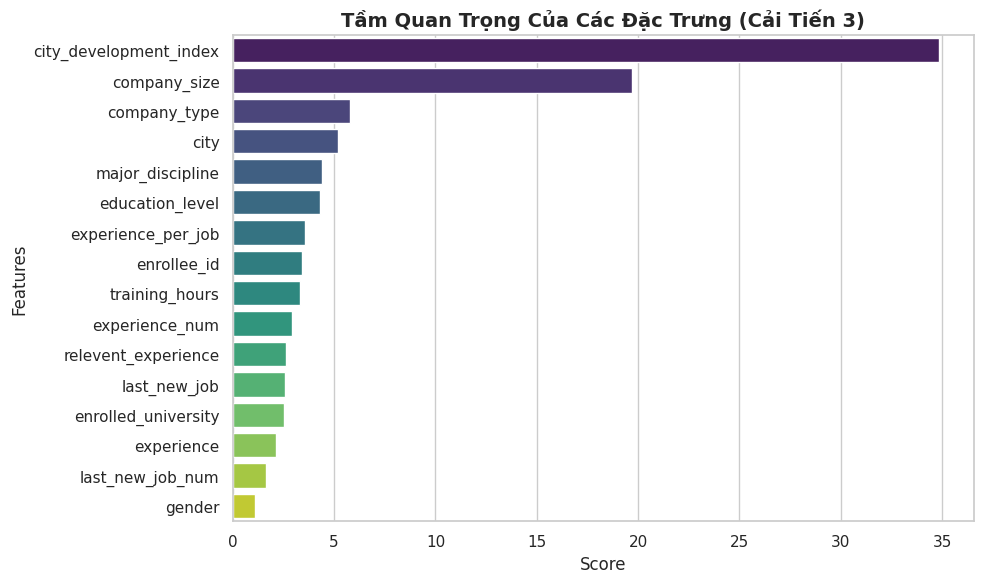

In [36]:
# Lấy feature importance từ mô hình tốt nhất (Mô hình Cải tiến 3)
feature_importances = model_cv3.get_feature_importance()
feature_names = X_fe.columns

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis', hue='Feature', legend=False)
plt.title('Tầm Quan Trọng Của Các Đặc Trưng (Cải Tiến 3)', fontsize=14, fontweight='bold')
plt.xlabel('Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### SHAP Values

Phân tích giá trị SHAP (SHAP Summary Values) cho thấy đặc trưng mới `experience_per_job` tương quan với khả năng nhảy việc cao. Những người có số năm làm việc trung bình trên mỗi công ty ngắn thể hiện tính cách linh hoạt, ít gắn bó dài hạn.

In [37]:
import shap
explainer = shap.TreeExplainer(model_cv3)
shap_values = explainer(X_fe_encoded)
print(shap_values.shape)

(19158, 16)


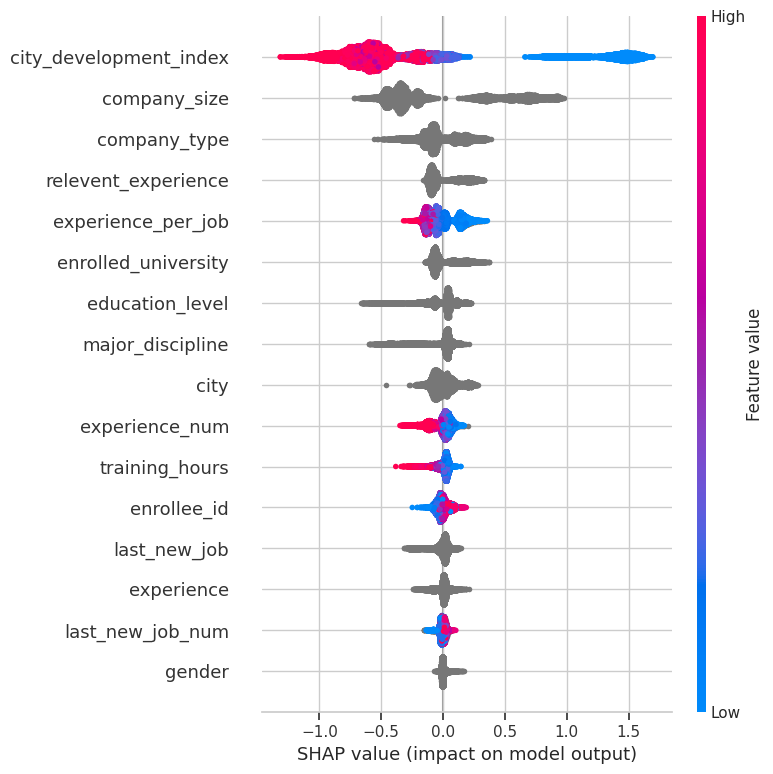

In [38]:
shap.summary_plot(shap_values, X_fe)

## So sánh kết quả giữa các mô hình

**Xu hướng thay đổi của các chỉ số**

* **F1-Score**: Tăng từ `0.5733` (Baseline) lên `0.6296` (Cải tiến 1) và đạt `0.6311` (Cải tiến 2), khẳng định việc cân bằng trọng số và điều chuẩn tham số đóng vai trò quyết định trong việc cải thiện độ nhạy với lớp thiểu số.
* **ROC-AUC**: Tăng đều qua từng bước cải tiến: `0.8034` $\rightarrow$ `0.8038` $\rightarrow$ `0.8043` $\rightarrow$ `0.8049`. Cải tiến 3 đạt ROC-AUC cao nhất nhờ bổ sung đặc trưng dẫn xuất.
* **LogLoss & Accuracy**: LogLoss của Baseline thấp hơn do mô hình thiên lệch về lớp 0. Khi bổ sung trọng số phạt cho lớp 1, LogLoss điều chỉnh về mức xấp xỉ 0.5188 - 0.5189, phản ánh đúng xác suất thực tế của bài toán mất cân bằng.

In [39]:
comparison_df = pd.DataFrame({
    "Mô hình": [
        "Baseline (Default CatBoost)",
        "Cải tiến 1 (Balanced weights)",
        "Cải tiến 2 (Grid Search Hyperparameters)",
        "Cải tiến 3 (Feature Engineering)"
    ],
    "LogLoss": [
        metrics_baseline["log_loss"],
        metrics_cv1["log_loss"],
        metrics_cv2["log_loss"],
        metrics_cv3["log_loss"]
    ],
    "Accuracy": [
        metrics_baseline["accuracy"],
        metrics_cv1["accuracy"],
        metrics_cv2["accuracy"],
        metrics_cv3["accuracy"]
    ],
    "F1-Score": [
        metrics_baseline["f1_score"],
        metrics_cv1["f1_score"],
        metrics_cv2["f1_score"],
        metrics_cv3["f1_score"]
    ],
    "ROC-AUC": [
        metrics_baseline["roc_auc"],
        metrics_cv1["roc_auc"],
        metrics_cv2["roc_auc"],
        metrics_cv3["roc_auc"]
    ]
})

display(comparison_df.round(4))

,Mô hình,LogLoss,Accuracy,F1-Score,ROC-AUC
0,Baseline (Default CatBoost),0.4355,0.7944,0.5733,0.8034
1,Cải tiến 1 (Balanced weights),0.5189,0.7798,0.6296,0.8038
2,Cải tiến 2 (Grid Search Hyperparameters),0.5189,0.7811,0.6311,0.8043
3,Cải tiến 3 (Feature Engineering),0.5188,0.7808,0.6307,0.8049


# Bonus: sử dụng built-in function của thư viện CatBoost

## Baseline (Sử dụng hàm cv built-in với dữ liệu thô)

In [ ]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool, cv

# danh sách các đặc trưng categorical gốc
cat_features = cat_cols.copy()

In [ ]:
print("=== [BUILT-IN] HUẤN LUYỆN BASELINE VỚI HÀM cv() ===")
train_pool_base = Pool(data=X_base, label=y_base, cat_features=cat_features)

params_base = {
    'loss_function': 'Logloss',
    'iterations': 300,
    'random_seed': 42,
    'verbose': 0,
    'task_type': 'GPU',
    'early_stopping_rounds': 50,
    'custom_metric': ['Logloss', 'AUC']
}

cv_baseline = cv(
    pool=train_pool_base,
    params=params_base,
    fold_count=5,
    shuffle=True,
    partition_random_seed=42,
    stratified=True,
    verbose=False
)

best_base_loss = cv_baseline['test-Logloss-mean'].min()
best_base_auc = cv_baseline['test-AUC-mean'].max()
print(f"-> Baseline - Best CV LogLoss: {best_base_loss:.5f} | Best CV ROC-AUC: {best_base_auc:.5f}\n")

=== [BUILT-IN] HUẤN LUYỆN BASELINE VỚI HÀM cv() ===
Training on fold [0/5]


Default metric period is 5 because AUC is/are not implemented for GPU


bestTest = 0.4288720843
bestIteration = 293
Training on fold [1/5]
bestTest = 0.4276343806
bestIteration = 298
Training on fold [2/5]
bestTest = 0.4247567643
bestIteration = 299
Training on fold [3/5]
bestTest = 0.4475311463
bestIteration = 248
Training on fold [4/5]
bestTest = 0.4377501948
bestIteration = 299
-> Baseline - Best CV LogLoss: 0.43335 | Best CV ROC-AUC: 0.80540



## Cải tiến 1 (Thêm auto_class_weights='Balanced')

In [ ]:
print("=== [BUILT-IN] HUẤN LUYỆN CẢI TIẾN 1 (BALANCED) VỚI HÀM cv() ===")
params_cv1 = params_base.copy()
params_cv1['auto_class_weights'] = 'Balanced'

cv_cv1 = cv(
    pool=train_pool_base,
    params=params_cv1,
    fold_count=5,
    shuffle=True,
    partition_random_seed=42,
    stratified=True,
    verbose=False
)

best_cv1_loss = cv_cv1['test-Logloss-mean'].min()
best_cv1_auc = cv_cv1['test-AUC-mean'].max()
print(f"-> Cải tiến 1 - Best CV LogLoss: {best_cv1_loss:.5f} | Best CV ROC-AUC: {best_cv1_auc:.5f}\n")

=== [BUILT-IN] HUẤN LUYỆN CẢI TIẾN 1 (BALANCED) VỚI HÀM cv() ===


Default metric period is 5 because AUC is/are not implemented for GPU


Training on fold [0/5]
bestTest = 0.5206965981
bestIteration = 299
Training on fold [1/5]
bestTest = 0.5205130015
bestIteration = 299
Training on fold [2/5]
bestTest = 0.5155809011
bestIteration = 297
Training on fold [3/5]
bestTest = 0.5439697437
bestIteration = 282
Training on fold [4/5]
bestTest = 0.5332509407
bestIteration = 298
-> Cải tiến 1 - Best CV LogLoss: 0.52683 | Best CV ROC-AUC: 0.80523



## Cải tiến 2 (Sử dụng grid_search built-in)

In [ ]:
print("=== [BUILT-IN] BẮT ĐẦU GRID SEARCH VỚI PHƯƠNG THỨC grid_search() ===")
grid_params = {
    'depth': [4, 5, 6, 7, 8],
    'l2_leaf_reg': [1, 3, 5, 7, 10]
}

# Khởi tạo mô hình CatBoostClassifier để chạy Grid Search
model_gs = CatBoostClassifier(
    task_type="GPU",
    iterations=300,
    auto_class_weights='Balanced',
    random_seed=42,
    early_stopping_rounds=50,
    verbose=False
)

grid_search_result = model_gs.grid_search(
    param_grid=grid_params,
    X=train_pool_base,
    cv=5,
    stratified=True,
    partition_random_seed=42,
    calc_cv_statistics=True,
    verbose=False
)

best_params_gs = grid_search_result['params']
print(f"-> Cấu hình tối ưu nhất tìm được: {best_params_gs}\n")

=== [BUILT-IN] BẮT ĐẦU GRID SEARCH VỚI PHƯƠNG THỨC grid_search() ===
bestTest = 0.5344432997
bestIteration = 297
bestTest = 0.5345478213
bestIteration = 299
bestTest = 0.5345433113
bestIteration = 293
bestTest = 0.5342581425
bestIteration = 299
bestTest = 0.5345848193
bestIteration = 299
bestTest = 0.5342929273
bestIteration = 298
bestTest = 0.5342878328
bestIteration = 270
bestTest = 0.5339277908
bestIteration = 276
bestTest = 0.5343436639
bestIteration = 297
bestTest = 0.5341645199
bestIteration = 298
bestTest = 0.5350760665
bestIteration = 184
bestTest = 0.5346009381
bestIteration = 275
bestTest = 0.5341723705
bestIteration = 279
bestTest = 0.5346697979
bestIteration = 207
bestTest = 0.5348335748
bestIteration = 148
bestTest = 0.5336657979
bestIteration = 216
bestTest = 0.5342313335
bestIteration = 164
bestTest = 0.5332914746
bestIteration = 237
bestTest = 0.53352883
bestIteration = 245
bestTest = 0.5333952445
bestIteration = 173
bestTest = 0.5343613277
bestIteration = 186
bestTest 

## Cải tiến 3 (Feature Engineering + hàm cv built-in)

In [ ]:
print("=== [BUILT-IN] HUẤN LUYỆN CẢI TIẾN 3 VỚI FEATURE ENGINEERING VÀ HÀM cv() ===")
# Sử dụng dataframe X_fe đã có sẵn từ bước Feature Engineering trước đó
train_pool_fe = Pool(data=X_fe, label=y_base, cat_features=cat_features)

params_cv3 = {
    'loss_function': 'Logloss',
    'iterations': 300,
    'depth': best_params_gs['depth'],
    'l2_leaf_reg': best_params_gs['l2_leaf_reg'],
    'auto_class_weights': 'Balanced',
    'random_seed': 42,
    'verbose': 0,
    'task_type': 'GPU',
    'early_stopping_rounds': 50,
    'custom_metric': ['Logloss', 'AUC']
}

cv_cv3 = cv(
    pool=train_pool_fe,
    params=params_cv3,
    fold_count=5,
    shuffle=True,
    partition_random_seed=42,
    stratified=True,
    verbose=False
)

best_cv3_loss = cv_cv3['test-Logloss-mean'].min()
best_cv3_auc = cv_cv3['test-AUC-mean'].max()
print(f"-> Cải tiến 3 - Best CV LogLoss: {best_cv3_loss:.5f} | Best CV ROC-AUC: {best_cv3_auc:.5f}")

=== [BUILT-IN] HUẤN LUYỆN CẢI TIẾN 3 VỚI FEATURE ENGINEERING VÀ HÀM cv() ===
Training on fold [0/5]


Default metric period is 5 because AUC is/are not implemented for GPU


bestTest = 0.5203494291
bestIteration = 299
Training on fold [1/5]
bestTest = 0.5194524334
bestIteration = 289
Training on fold [2/5]
bestTest = 0.5144710026
bestIteration = 298
Training on fold [3/5]
bestTest = 0.5427981652
bestIteration = 208
Training on fold [4/5]
bestTest = 0.5339287828
bestIteration = 172
-> Cải tiến 3 - Best CV LogLoss: 0.52633 | Best CV ROC-AUC: 0.80524


### Bảng so sánh kết quả giữa các mô hình (Sử dụng hàm Built-in)

In [ ]:
import pandas as pd

# Trích xuất các chỉ số tốt nhất từ kết quả CV của các mô hình built-in
comparison_builtin_df = pd.DataFrame({
    "Mô hình (Built-in)": [
        "Baseline (Default)",
        "Cải tiến 1 (Balanced)",
        "Cải tiến 2 (Grid Search)",
        "Cải tiến 3 (Feature Engineering)"
    ],
    "CV LogLoss": [
        best_base_loss,
        best_cv1_loss,
        # Lấy LogLoss nhỏ nhất của cấu hình tốt nhất trong Grid Search
        min(grid_search_result['cv_results']['test-Logloss-mean']),
        best_cv3_loss
    ],
    "CV ROC-AUC": [
        best_base_auc,
        best_cv1_auc,
        # Lấy ROC-AUC lớn nhất của cấu hình tốt nhất trong Grid Search
        max(grid_search_result['cv_results']['test-AUC-mean']),
        best_cv3_auc
    ]
})

display(comparison_builtin_df.round(5))

,Mô hình (Built-in),CV LogLoss,CV ROC-AUC
0,Baseline (Default),0.43335,0.80540
1,Cải tiến 1 (Balanced),0.52683,0.80523
2,Cải tiến 2 (Grid Search),0.52622,0.80428
3,Cải tiến 3 (Feature Engineering),0.52633,0.80524
